# Importancia das variaveis nos cinco modelos de predicao de obito por chikungunya

Este notebook calcula a importancia nativa de cada uma das 28 variaveis preditoras para os cinco algoritmos ja treinados na fase de modelagem: Regressao Logistica, Arvore de Decisao (CART), Random Forest, XGBoost e LightGBM.
Os cinco modelos usados aqui foram retreinados depois que uma etapa anterior do pipeline de dados identificou e removeu do conjunto de preditores uma variavel derivada com vazamento temporal, reduzindo o numero de variaveis originais de 29 para 28.
Este notebook recalcula do zero toda a importancia de variaveis com os cinco modelos retreinados nessa nova versao do conjunto de preditores, substituindo integralmente os resultados anteriores, que ainda incluiam a variavel removida.
Para os quatro modelos baseados em arvore, Arvore de Decisao, Random Forest, XGBoost e LightGBM, a importancia usada e a medida nativa de cada biblioteca: Gini, tambem chamada de MDI, para os dois primeiros, e ganho (gain) para XGBoost e LightGBM.
Para a Regressao Logistica, a importancia agregada por variavel e a soma dos valores absolutos dos coeficientes ajustados, somada entre todas as categorias quando a variavel e categorica e foi codificada em multiplas colunas por one hot encoding.
Nenhum modelo e retreinado neste notebook, os cinco pipelines usados sao exatamente os artefatos finais salvos em `output/modelos/`, ja ajustados em todo o periodo de treino de 2020 a 2023.
O notebook produz uma tabela ranqueada por modelo, uma tabela consolidada com o rank de cada variavel nos cinco modelos e o rank medio entre eles, a concordancia entre os cinco rankings por correlacao de Spearman, e uma tabela detalhada de razao de chances por categoria para a Regressao Logistica.
A comparacao destes resultados com a literatura cientifica sobre fatores de risco de obito por chikungunya nao e feita neste notebook, e fica para uma etapa posterior fora deste notebook.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessing.py`, e cria os diretorios de saida usados ao longo do notebook.
As tabelas sao salvas em `analysis/results_importancia/`, sobrescrevendo os arquivos calculados antes da remocao da variavel com vazamento temporal, e os graficos em `analysis/plots/importancia/`.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessing

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_importancia"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "importancia"

DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_VARIAVEIS_EM_DESTAQUE = 10

Carrega apenas os preditores do treino completo, ja construidos pelo pipeline de dados sem a variavel com vazamento temporal, para obter a lista oficial das 28 variaveis originais e separar as numericas das categoricas.
Essa separacao segue exatamente a mesma convencao usada na fase de modelagem, em `utils/preprocessing.py`, e nenhuma linha do treino e usada para ajustar nada neste notebook, apenas para nomear as colunas.

In [2]:
X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")

COLUNAS_NUMERICAS = preprocessing.COLUNAS_NUMERICAS
COLUNAS_CATEGORICAS = preprocessing.obter_colunas_categoricas(X_train)
VARIAVEIS_ORIGINAIS = list(X_train.columns)

len(VARIAVEIS_ORIGINAIS), len(COLUNAS_NUMERICAS), len(COLUNAS_CATEGORICAS)

(28, 2, 26)

Carrega os cinco pipelines finais salvos pela fase de modelagem, cada um ja ajustado em todo o periodo de treino de 2020 a 2023 com as 28 variaveis preditoras atuais.
Sao usados exclusivamente os artefatos originais, sem o sufixo `_calibrado`, ja que o reescalonador de calibracao e unidimensional e nao contem nenhuma informacao sobre a importancia das 28 variaveis preditoras.

In [3]:
modelos = {algoritmo: joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib") for algoritmo in ALGORITMOS}

{algoritmo: type(modelo.named_steps["classificador"]).__name__ for algoritmo, modelo in modelos.items()}

{'regressao_logistica': 'LogisticRegression',
 'arvore_decisao': 'DecisionTreeClassifier',
 'random_forest': 'RandomForestClassifier',
 'xgboost': 'XGBClassifier',
 'lightgbm': 'LGBMClassifier'}

Define duas funcoes auxiliares usadas pelos tres modelos que dependem do `ColumnTransformer` de codificacao one hot: Regressao Logistica, Arvore de Decisao e Random Forest.
A primeira funcao recupera a variavel original correspondente a uma coluna codificada: uma coluna numerica mantem o proprio nome apos o prefixo `numericas__`, enquanto uma coluna categorica tem o formato `categoricas__{variavel}_{categoria}`, identificado comparando esse sufixo com a lista das 26 variaveis categoricas.
A segunda funcao soma, para cada variavel original, os valores informados em todas as colunas codificadas que pertencem a ela, o que, para a Regressao Logistica, corresponde exatamente a soma dos valores absolutos dos coeficientes das categorias daquela variavel.

In [4]:
def mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador == "numericas":
        return nome_apos_prefixo

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            return variavel_categorica

    raise ValueError(f"Nenhuma variavel original encontrada para {nome_coluna_codificada}")


def agregar_importancia_one_hot_por_variavel(preprocessador, valores_por_coluna_codificada):
    nomes_colunas_codificadas = preprocessador.get_feature_names_out()
    importancia_por_variavel = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)

    for nome_coluna_codificada, valor in zip(nomes_colunas_codificadas, valores_por_coluna_codificada):
        variavel_original = mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
        importancia_por_variavel[variavel_original] += valor

    return importancia_por_variavel

## Regressao Logistica

A Regressao Logistica usa o `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e o valor absoluto do coeficiente ajustado pelo classificador, antes da agregacao pela funcao definida acima.
O sinal original dos coeficientes nao e descartado, e e reaproveitado mais adiante neste notebook na tabela de razao de chances por categoria, ja que a agregacao por soma de valores absolutos remove a direcao do efeito de cada categoria.

In [5]:
preprocessador_regressao_logistica = modelos["regressao_logistica"].named_steps["preprocessador"]
coeficientes_regressao_logistica = modelos["regressao_logistica"].named_steps["classificador"].coef_[0]

importancia_regressao_logistica = agregar_importancia_one_hot_por_variavel(
    preprocessador_regressao_logistica, np.abs(coeficientes_regressao_logistica)
)
importancia_regressao_logistica.sort_values(ascending=False).head(10)

CS_ESCOL_N      1.427777
CS_RACA         0.899588
MACRORREGIAO    0.888659
CS_GESTANT      0.881452
VOMITO          0.634198
RENAL           0.551540
IDADE_ANOS      0.549973
HEPATOPAT       0.514307
ARTRITE         0.401897
LEUCOPENIA      0.396387
dtype: float64

## Arvore de Decisao (CART)

A Arvore de Decisao usa o mesmo tipo de `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e a importancia de Gini, tambem chamada de MDI (mean decrease in impurity), calculada diretamente pelo `DecisionTreeClassifier` ja ajustado.

In [6]:
preprocessador_arvore_decisao = modelos["arvore_decisao"].named_steps["preprocessador"]
mdi_arvore_decisao = modelos["arvore_decisao"].named_steps["classificador"].feature_importances_

importancia_arvore_decisao = agregar_importancia_one_hot_por_variavel(
    preprocessador_arvore_decisao, mdi_arvore_decisao
)
importancia_arvore_decisao.sort_values(ascending=False).head(10)

IDADE_ANOS    0.782443
VOMITO        0.125362
DOR_RETRO     0.041986
CS_ESCOL_N    0.027944
CS_RACA       0.022264
FEBRE         0.000000
CS_SEXO       0.000000
MIALGIA       0.000000
EXANTEMA      0.000000
NAUSEA        0.000000
dtype: float64

## Random Forest

O Random Forest usa o mesmo tipo de pre-processamento one hot da Arvore de Decisao, e a importancia bruta de cada coluna codificada e a media da importancia de Gini entre todas as arvores do ensemble, tambem calculada diretamente pelo `RandomForestClassifier` ja ajustado.

In [7]:
preprocessador_random_forest = modelos["random_forest"].named_steps["preprocessador"]
mdi_random_forest = modelos["random_forest"].named_steps["classificador"].feature_importances_

importancia_random_forest = agregar_importancia_one_hot_por_variavel(
    preprocessador_random_forest, mdi_random_forest
)
importancia_random_forest.sort_values(ascending=False).head(10)

IDADE_ANOS            0.197837
SEMANA_EPI_SIN_PRI    0.098652
CS_ESCOL_N            0.089285
MACRORREGIAO          0.052936
CS_RACA               0.052900
VOMITO                0.041374
HIPERTENSA            0.040334
CS_GESTANT            0.036680
CS_SEXO               0.035808
EXANTEMA              0.033857
dtype: float64

## XGBoost

O XGBoost usa o imputador categorico nativo de `utils/preprocessing.py`, que preserva os nomes originais das 28 variaveis sem codificacao one hot, e a importancia nativa usada e o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado.
O booster so reporta ganho para variaveis usadas em pelo menos uma divisao de pelo menos uma arvore, e o codigo abaixo preenche com zero qualquer variavel sem nenhuma divisao, para que as 28 variaveis sempre apareçam completas na tabela final, independente de quantas o modelo final efetivamente use.

In [8]:
booster_xgboost = modelos["xgboost"].named_steps["classificador"].get_booster()
ganho_por_variavel_usada_xgboost = booster_xgboost.get_score(importance_type="gain")

importancia_xgboost = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)
for variavel, ganho in ganho_por_variavel_usada_xgboost.items():
    importancia_xgboost[variavel] = ganho

importancia_xgboost.sort_values(ascending=False).head(10)

IDADE_ANOS      207.251282
VOMITO          118.303169
CS_ESCOL_N       90.395721
HEPATOPAT        87.144478
ARTRITE          83.487869
CS_GESTANT       83.474426
MACRORREGIAO     82.473717
CEFALEIA         75.678146
CS_SEXO          70.576813
CONJUNTVIT       68.567986
dtype: float64

## LightGBM

O LightGBM usa o mesmo imputador categorico nativo do XGBoost, ja que o LightGBM tambem reconhece diretamente colunas do tipo `category`.
A importancia nativa usada e tambem o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado, que ja retorna um valor, possivelmente zero, para cada uma das 28 variaveis, sem precisar do preenchimento manual usado para o XGBoost.

In [9]:
booster_lightgbm = modelos["lightgbm"].named_steps["classificador"].booster_

importancia_lightgbm = pd.Series(
    booster_lightgbm.feature_importance(importance_type="gain"),
    index=booster_lightgbm.feature_name(),
).reindex(VARIAVEIS_ORIGINAIS)

importancia_lightgbm.sort_values(ascending=False).head(10)

IDADE_ANOS            29382.849718
SEMANA_EPI_SIN_PRI     8070.581828
CS_ESCOL_N             7905.073860
VOMITO                 3797.415233
CS_RACA                1894.199388
MACRORREGIAO           1669.195343
CS_GESTANT             1615.247667
CS_SEXO                1568.352197
DOR_RETRO              1192.887932
NAUSEA                 1068.157961
dtype: float64

## Tabela consolidada de importancia bruta

Reune as cinco series de importancia num unico dicionario, na mesma ordem dos cinco algoritmos usada pelo restante do notebook, e organiza o resultado numa unica tabela com as 28 variaveis nas linhas e os cinco algoritmos nas colunas.
Essa tabela bruta e a base tanto das tabelas individuais ranqueadas por modelo quanto da tabela consolidada entre modelos e da matriz de concordancia de Spearman, mais adiante, e e salva em `analysis/results_importancia/importancia_bruta_por_modelo.csv`.

In [10]:
IMPORTANCIA_POR_ALGORITMO = {
    "regressao_logistica": importancia_regressao_logistica,
    "arvore_decisao": importancia_arvore_decisao,
    "random_forest": importancia_random_forest,
    "xgboost": importancia_xgboost,
    "lightgbm": importancia_lightgbm,
}

tabela_importancia_bruta = pd.DataFrame(IMPORTANCIA_POR_ALGORITMO).loc[VARIAVEIS_ORIGINAIS]

tabela_importancia_bruta.rename_axis("variavel").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "importancia_bruta_por_modelo.csv", index=False
)
tabela_importancia_bruta

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
CS_SEXO,0.196328,0.000000,0.035808,70.576813,1568.352197
CS_GESTANT,0.881452,0.000000,0.036680,83.474426,1615.247667
CS_RACA,0.899588,0.022264,0.052900,58.794392,1894.199388
CS_ESCOL_N,1.427777,0.027944,0.089285,90.395721,7905.073860
FEBRE,0.103012,0.000000,0.017500,0.000000,320.078811
MIALGIA,0.003277,0.000000,0.028274,0.000000,372.635448
CEFALEIA,0.242258,0.000000,0.033628,75.678146,1015.244436
EXANTEMA,0.372033,0.000000,0.033857,66.864983,920.973981
VOMITO,0.634198,0.125362,0.041374,118.303169,3797.415233
NAUSEA,0.076208,0.000000,0.027769,0.000000,1068.157961


Para cada algoritmo, ordena as 28 variaveis pela importancia em ordem decrescente, atribui um rank de 1 a 28, e marca como `destaque_top10` as 10 variaveis de maior importancia daquele modelo.
Cada tabela individual e salva separadamente em `analysis/results_importancia/importancia_{algoritmo}.csv`, com a variavel, a importancia bruta, o rank e a marcacao de top 10.

In [11]:
tabelas_ranqueadas_por_algoritmo = {}
for algoritmo in ALGORITMOS:
    tabela_ranqueada = (
        tabela_importancia_bruta[algoritmo].rename("importancia").rename_axis("variavel").reset_index()
    )
    tabela_ranqueada = tabela_ranqueada.sort_values("importancia", ascending=False).reset_index(drop=True)
    tabela_ranqueada["rank"] = tabela_ranqueada.index + 1
    tabela_ranqueada["destaque_top10"] = tabela_ranqueada["rank"] <= NUMERO_VARIAVEIS_EM_DESTAQUE

    tabela_ranqueada.to_csv(DIRETORIO_RESULTADOS_ANALISE / f"importancia_{algoritmo}.csv", index=False)
    tabelas_ranqueadas_por_algoritmo[algoritmo] = tabela_ranqueada

tabelas_ranqueadas_por_algoritmo["random_forest"].head(10)

,variavel,importancia,rank,destaque_top10
0,IDADE_ANOS,0.197837,1,True
1,SEMANA_EPI_SIN_PRI,0.098652,2,True
2,CS_ESCOL_N,0.089285,3,True
3,MACRORREGIAO,0.052936,4,True
4,CS_RACA,0.052900,5,True
5,VOMITO,0.041374,6,True
6,HIPERTENSA,0.040334,7,True
7,CS_GESTANT,0.036680,8,True
8,CS_SEXO,0.035808,9,True
9,EXANTEMA,0.033857,10,True


Gera, num painel com um grafico de barras horizontais por algoritmo, as 10 variaveis de maior importancia de cada um dos cinco modelos, da menos para a mais importante de baixo para cima.
Cada painel usa a propria escala do eixo de importancia, ja que a unidade de medida difere entre os modelos: valor absoluto de coeficiente para a Regressao Logistica, importancia de Gini para Arvore de Decisao e Random Forest, e ganho para XGBoost e LightGBM.
O grafico e salvo em `analysis/plots/importancia/top10_variaveis_por_modelo.png`.

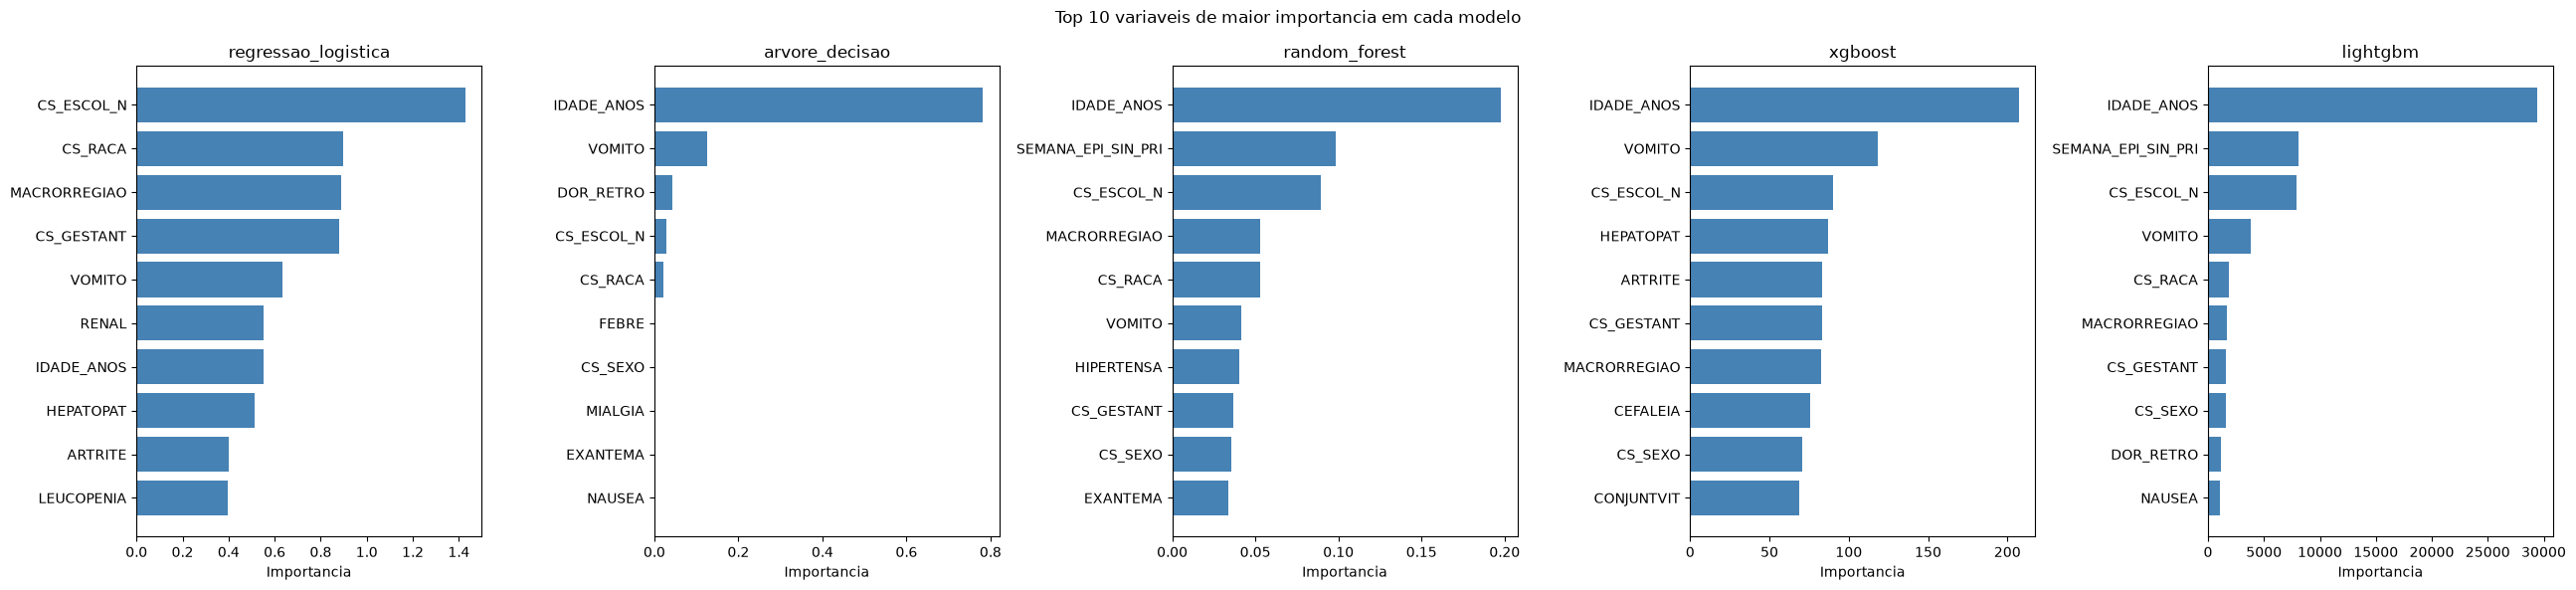

In [12]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(26, 6))

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    top10_algoritmo = tabelas_ranqueadas_por_algoritmo[algoritmo].head(NUMERO_VARIAVEIS_EM_DESTAQUE).iloc[::-1]
    eixo_atual.barh(top10_algoritmo["variavel"], top10_algoritmo["importancia"], color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Importancia")

figura.suptitle("Top 10 variaveis de maior importancia em cada modelo")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "top10_variaveis_por_modelo.png", dpi=150)
plt.show()

## Tabela consolidada entre os cinco modelos

Converte a importancia bruta de cada algoritmo em rank, de 1, a mais importante, a 28, a menos importante, usando rank medio para desempatar variaveis de importancia exatamente igual.
Calcula o rank medio entre os cinco modelos para cada variavel, e ordena a tabela final por esse rank medio, da variavel mais importante em media a menos importante em media.
A tabela e salva em `analysis/results_importancia/ranking_consolidado_5_modelos.csv`.

In [13]:
tabela_rank_por_algoritmo = tabela_importancia_bruta.rank(ascending=False, method="average")
tabela_rank_por_algoritmo = tabela_rank_por_algoritmo.rename(
    columns={algoritmo: f"rank_{algoritmo}" for algoritmo in ALGORITMOS}
)
tabela_rank_por_algoritmo["rank_medio"] = tabela_rank_por_algoritmo.mean(axis=1)

tabela_rank_consolidada = (
    tabela_rank_por_algoritmo.rename_axis("variavel")
    .reset_index()
    .sort_values("rank_medio")
    .reset_index(drop=True)
)
tabela_rank_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "ranking_consolidado_5_modelos.csv", index=False
)
tabela_rank_consolidada

,variavel,rank_regressao_logistica,rank_arvore_decisao,rank_random_forest,rank_xgboost,rank_lightgbm,rank_medio
0,IDADE_ANOS,7.0,1.0,1.0,1.0,1.0,2.2
1,CS_ESCOL_N,1.0,4.0,3.0,3.0,3.0,2.8
2,VOMITO,5.0,2.0,6.0,2.0,4.0,3.8
3,CS_RACA,2.0,5.0,5.0,14.0,5.0,6.2
4,MACRORREGIAO,3.0,17.0,4.0,7.0,6.0,7.4
5,CS_GESTANT,4.0,17.0,8.0,6.0,7.0,8.4
6,DOR_RETRO,16.0,3.0,18.0,11.0,9.0,11.4
7,ARTRITE,9.0,17.0,16.0,5.0,11.0,11.6
8,CS_SEXO,19.0,17.0,9.0,9.0,8.0,12.4
9,SEMANA_EPI_SIN_PRI,26.0,17.0,2.0,16.0,2.0,12.6


## Concordancia entre os rankings dos cinco modelos

Calcula a correlacao de Spearman entre as cinco colunas de importancia bruta, o que equivale a correlacionar os rankings das 28 variaveis entre cada par de modelos, numa matriz 5 por 5.
Uma correlacao proxima de 1 indica que dois modelos ordenam as 28 variaveis de forma quase identica, enquanto uma correlacao proxima de 0 indica rankings praticamente independentes entre si.
A matriz e salva em `analysis/results_importancia/concordancia_spearman_entre_modelos.csv`.

In [14]:
matriz_spearman = tabela_importancia_bruta.corr(method="spearman")

matriz_spearman.rename_axis("algoritmo").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "concordancia_spearman_entre_modelos.csv", index=False
)
matriz_spearman

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
regressao_logistica,1.000000,0.464660,0.436782,0.728872,0.518883
arvore_decisao,0.464660,1.000000,0.457284,0.499629,0.585127
random_forest,0.436782,0.457284,1.000000,0.513174,0.759168
xgboost,0.728872,0.499629,0.513174,1.000000,0.695941
lightgbm,0.518883,0.585127,0.759168,0.695941,1.000000


Gera um heatmap da matriz de concordancia de Spearman entre os cinco modelos, com o valor de cada par anotado diretamente sobre a celula correspondente.
O grafico e salvo em `analysis/plots/importancia/heatmap_concordancia_spearman.png`.

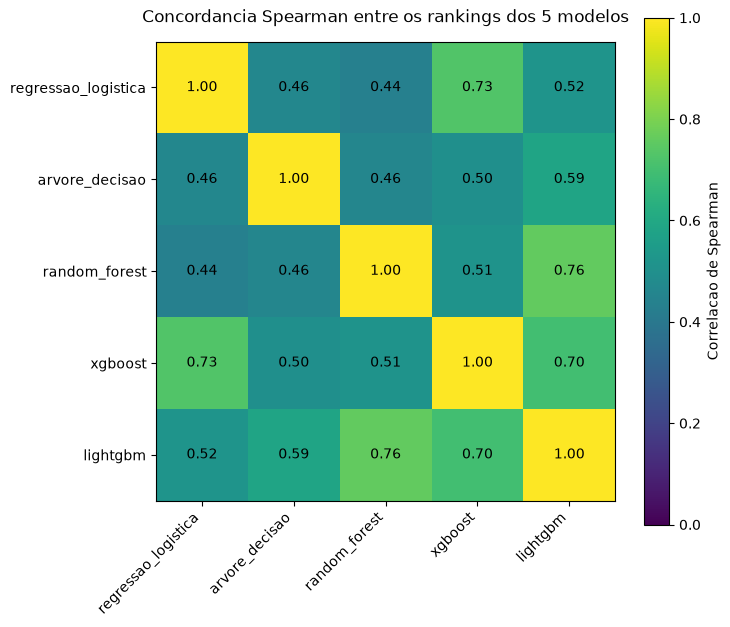

In [15]:
figura, eixo = plt.subplots(figsize=(7.5, 6.5))
mapa_cores = eixo.imshow(matriz_spearman, cmap="viridis", vmin=0, vmax=1)

eixo.set_xticks(range(len(ALGORITMOS)))
eixo.set_xticklabels(ALGORITMOS, rotation=45, ha="right")
eixo.set_yticks(range(len(ALGORITMOS)))
eixo.set_yticklabels(ALGORITMOS)

for linha in range(len(ALGORITMOS)):
    for coluna in range(len(ALGORITMOS)):
        eixo.text(
            coluna, linha, f"{matriz_spearman.iloc[linha, coluna]:.2f}", ha="center", va="center", color="black"
        )

eixo.set_title("Concordancia Spearman entre os rankings dos 5 modelos", pad=14)
figura.colorbar(mapa_cores, ax=eixo, label="Correlacao de Spearman")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "heatmap_concordancia_spearman.png", dpi=150)
plt.show()

## Razao de chances por categoria na Regressao Logistica

A importancia agregada por variavel, usada nas secoes anteriores, soma os valores absolutos dos coeficientes de todas as categorias de uma mesma variavel, o que e adequado para comparar a Regressao Logistica aos demais modelos, mas descarta tanto o sinal quanto a magnitude isolada de cada categoria.
Esta secao recupera, para cada uma das 26 variaveis categoricas, o coeficiente e a razao de chances, `exp(coeficiente)`, de cada categoria individualmente, o nivel de detalhe clinicamente mais interpretavel para esse modelo.
Uma razao de chances acima de 1 indica que a categoria, isolada, esta associada a uma chance maior de obito em relacao ao restante do modelo ajustado, e uma razao de chances abaixo de 1 indica o efeito inverso.
A tabela e salva em `analysis/results_importancia/razao_de_chances_por_categoria_regressao_logistica.csv`.

In [16]:
nomes_colunas_codificadas_regressao_logistica = preprocessador_regressao_logistica.get_feature_names_out()

linhas_razao_de_chances = []
for nome_coluna_codificada, coeficiente in zip(
    nomes_colunas_codificadas_regressao_logistica, coeficientes_regressao_logistica
):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador != "categoricas":
        continue

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            categoria = nome_apos_prefixo[len(variavel_categorica) + 1 :]
            linhas_razao_de_chances.append(
                {
                    "variavel": variavel_categorica,
                    "categoria": categoria,
                    "coeficiente": coeficiente,
                    "razao_de_chances": np.exp(coeficiente),
                }
            )
            break

tabela_razao_de_chances_categorica = pd.DataFrame(linhas_razao_de_chances)
tabela_razao_de_chances_categorica["categoria"] = tabela_razao_de_chances_categorica["categoria"].apply(
    lambda valor: "ausente_sem_imputacao" if valor is None or valor == "None" else valor
)
tabela_razao_de_chances_categorica = tabela_razao_de_chances_categorica.sort_values(
    "razao_de_chances", ascending=False
).reset_index(drop=True)

tabela_razao_de_chances_categorica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "razao_de_chances_por_categoria_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_categorica.head(10)

,variavel,categoria,coeficiente,razao_de_chances
0,VOMITO,1,0.318737,1.375390
1,MACRORREGIAO,Centro-Oeste,0.296257,1.344815
2,RENAL,1,0.277409,1.319705
3,HEPATOPAT,1,0.258792,1.295364
4,CS_ESCOL_N,4,0.245281,1.277980
5,CS_RACA,4,0.242555,1.274502
6,ARTRITE,2,0.202587,1.224566
7,LEUCOPENIA,1,0.199832,1.221197
8,DOR_COSTAS,2,0.198164,1.219163
9,CS_ESCOL_N,6,0.194809,1.215079


A categoria `ausente_sem_imputacao` de `CS_ESCOL_N`, visivel na tabela quando a variavel aparece, corresponde a 907 dos 7171 casos de treino cujo nivel de escolaridade nao foi informado.
Esses casos nao foram convertidos para a categoria constante `ausente`, usada para todas as demais variaveis categoricas, porque o valor ausente nessa coluna especifica e representado no dado tratado pelo objeto `None`, que o `SimpleImputer` de `scikit-learn` nao reconhece como ausente numa coluna de tipo texto.
Essa e uma particularidade pontual deste pipeline ja treinado, e afeta apenas o rotulo dessa categoria especifica na tabela de razao de chances, sem nenhum efeito sobre a importancia agregada de `CS_ESCOL_N` nas secoes anteriores, nem sobre nenhuma outra das 28 variaveis.

In [17]:
numero_casos_categoria_ausente_sem_imputacao = int(X_train["CS_ESCOL_N"].isna().sum())
numero_casos_categoria_ausente_sem_imputacao, len(X_train)

(907, 7171)

Como os dois preditores numericos, `IDADE_ANOS` e `SEMANA_EPI_SIN_PRI`, foram padronizados antes do ajuste da Regressao Logistica, cada um tem um unico coeficiente, e a razao de chances correspondente e por aumento de um desvio padrao, nao por uma unidade bruta da variavel, como um ano de idade.
Esta tabela complementar reune o coeficiente e a razao de chances por desvio padrao desses dois preditores, e e salva em `analysis/results_importancia/coeficientes_variaveis_numericas_regressao_logistica.csv`.

In [18]:
linhas_razao_de_chances_numericas = []
for variavel_numerica in COLUNAS_NUMERICAS:
    indice_coluna = list(nomes_colunas_codificadas_regressao_logistica).index(f"numericas__{variavel_numerica}")
    coeficiente = coeficientes_regressao_logistica[indice_coluna]
    linhas_razao_de_chances_numericas.append(
        {
            "variavel": variavel_numerica,
            "coeficiente_por_desvio_padrao": coeficiente,
            "razao_de_chances_por_desvio_padrao": np.exp(coeficiente),
        }
    )

tabela_razao_de_chances_numerica = (
    pd.DataFrame(linhas_razao_de_chances_numericas)
    .sort_values("razao_de_chances_por_desvio_padrao", ascending=False)
    .reset_index(drop=True)
)

tabela_razao_de_chances_numerica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "coeficientes_variaveis_numericas_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_numerica

,variavel,coeficiente_por_desvio_padrao,razao_de_chances_por_desvio_padrao
0,IDADE_ANOS,0.549973,1.733207
1,SEMANA_EPI_SIN_PRI,0.064272,1.066382


## Sintese dos achados

Idade (`IDADE_ANOS`) e a variavel de maior importancia media entre os cinco modelos, com rank medio de 2,2, seguida por escolaridade (`CS_ESCOL_N`), com rank medio de 2,8, por vomito (`VOMITO`), com rank medio de 3,8, por raca ou cor (`CS_RACA`), com rank medio de 6,2, e por macrorregiao de residencia (`MACRORREGIAO`), com rank medio de 7,4.
Idade e a variavel de maior importancia isolada em quatro dos cinco modelos, Arvore de Decisao, Random Forest, XGBoost e LightGBM, e aparece apenas na setima posicao na Regressao Logistica, o unico dos cinco modelos em que ela nao lidera o ranking.

`CS_ESCOL_N` e a variavel categorica de maior cardinalidade do conjunto de preditores, com 12 categorias incluindo a categoria de valor ausente, e e a variavel de maior importancia bruta isolada na Regressao Logistica, 1,43, acima inclusive de idade.
Essa primeira posicao na Regressao Logistica e parcialmente explicada pela cardinalidade dessa variavel, ja que a soma dos valores absolutos de 12 coeficientes de categoria favorece mecanicamente essa variavel frente a um preditor numerico como idade, que contribui com um unico coeficiente para essa soma.
Essa ressalva, porem, nao invalida a posicao de `CS_ESCOL_N` entre as variaveis mais relevantes, porque os quatro modelos restantes tambem a colocam entre as cinco variaveis mais importantes, terceira no Random Forest, no XGBoost e no LightGBM, e quarta na Arvore de Decisao.

`VOMITO`, o sintoma de maior importancia media entre os cinco modelos, aparece no top 10 dos cinco ao mesmo tempo, assim como idade e escolaridade, com a segunda posicao na Arvore de Decisao e no XGBoost, a quarta no LightGBM, a quinta na Regressao Logistica e a sexta no Random Forest.

A Arvore de Decisao final selecionada pela busca de hiperparametros tem profundidade maxima 3 e apenas 8 folhas, o que limita a 5 o numero de variaveis usadas em pelo menos uma divisao, `IDADE_ANOS`, `VOMITO`, `DOR_RETRO`, `CS_ESCOL_N` e `CS_RACA`, deixando as demais 23 variaveis, incluindo `MACRORREGIAO`, com importancia de Gini exatamente igual a zero.
O XGBoost tambem deixa de usar 5 das 28 variaveis em qualquer divisao de qualquer arvore, `MIALGIA`, `NAUSEA`, `FEBRE`, `HEMATOLOG` e `ACIDO_PEPT`, todas com ganho exatamente igual a zero, mas distribui o restante do ganho de forma bem menos concentrada do que a Arvore de Decisao entre as 23 variaveis restantes.
O Random Forest e o LightGBM, em contraste, atribuem importancia nativa maior que zero a todas as 28 variaveis, ainda que de magnitude muito pequena para as ultimas colocadas de cada ranking.

A correlacao de Spearman entre os rankings dos cinco modelos varia de 0,437, entre Regressao Logistica e Random Forest, a 0,759, entre Random Forest e LightGBM, com media de 0,566 entre os dez pares possiveis de modelos.
Random Forest e LightGBM formam o par mais concordante, seguido de perto por Regressao Logistica e XGBoost, com correlacao de 0,729.
Considerando a concordancia media de cada modelo com os outros quatro, a Arvore de Decisao e o modelo mais discordante, com media de 0,502, consistente com sua importancia concentrada em apenas 5 das 28 variaveis, enquanto o LightGBM e o modelo mais concordante com os demais, com media de 0,640.

Na tabela de razao de chances por categoria da Regressao Logistica, a categoria de maior razao de chances isolada e a categoria que indica presenca do sintoma em `VOMITO`, com razao de chances de 1,38, seguida pela categoria Centro-Oeste de `MACRORREGIAO`, com razao de chances de 1,34.
Entre as cinco categorias de `MACRORREGIAO`, Centro-Oeste e Sudeste tem razao de chances acima de 1, 1,34 e 1,16 respectivamente, Nordeste e Sul ficam muito proximas de 1, 0,99 e 0,98, e Norte tem a menor razao de chances entre as cinco, 0,66, a segunda menor de toda a tabela de categorias, atras apenas da categoria 9 de `CS_RACA`, com razao de chances de 0,64.
Os dois preditores numericos tem razao de chances por desvio padrao de 1,73 para idade e 1,07 para a semana epidemiologica de inicio dos sintomas, sempre por um aumento de um desvio padrao, e nao por uma unidade bruta da variavel, ja que os dois foram padronizados antes do ajuste da Regressao Logistica.
Os codigos de categoria de `CS_RACA` e das demais variaveis categoricas codificadas numericamente seguem a codificacao original do SINAN e nao sao decodificados neste notebook, enquanto as categorias de `MACRORREGIAO` ja chegam nomeadas pelo pipeline de dados.

Este notebook se limita a produzir e descrever estes resultados quantitativos internos ao estudo, sem comparacao com a literatura cientifica sobre fatores de risco de obito por chikungunya, etapa que fica para um momento posterior fora deste notebook.